# **Análise exploratória dos dados**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("C:/Users/Maria/AC_project/data/training_data.csv")



# 5. Locais onde há sopro (só faz sentido para Present)
(df.loc[df["Murmur"] == "Present", "Murmur locations"].value_counts().head(10))

# 6. Demografia vs. classe
(df.groupby("Murmur")["Age"].value_counts().unstack(0))   # grupos etários
(pd.crosstab(df["Sex"], df["Murmur"], normalize="index").round(3))
(df.groupby("Murmur")[["Height", "Weight"]].describe().T)

# 7. Campanha (as duas campanhas podem ter distribuições diferentes)
(pd.crosstab(df["Campaign"], df["Murmur"]))

Murmur,Absent,Present,Unknown
Campaign,,,
CC2014,302,63,20
CC2015,393,116,48


### **Perceber o shape**

In [26]:
print(df.shape)
df.info()
print(df["Patient ID"].is_unique)

(942, 24)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 942 entries, 0 to 941
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Patient ID                942 non-null    int64  
 1   Recording locations:      942 non-null    object 
 2   Age                       868 non-null    object 
 3   Sex                       942 non-null    object 
 4   Height                    826 non-null    float64
 5   Weight                    837 non-null    float64
 6   Pregnancy status          942 non-null    bool   
 7   Murmur                    942 non-null    object 
 8   Murmur locations          179 non-null    object 
 9   Most audible location     179 non-null    object 
 10  Systolic murmur timing    178 non-null    object 
 11  Systolic murmur shape     178 non-null    object 
 12  Systolic murmur grading   178 non-null    object 
 13  Systolic murmur pitch     178 non-null    object 
 14  

### **Gráfico de distribuição da classe alvo**

IMBALANCEEEEE

Murmur
Absent     695
Present    179
Unknown     68
Name: count, dtype: int64
Murmur
Absent     0.738
Present    0.190
Unknown    0.072
Name: proportion, dtype: float64


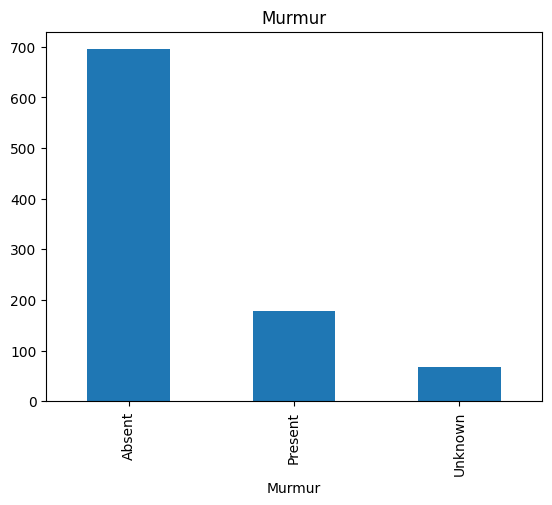

In [14]:
# 3. Distribuição da classe alvo (Murmur)
print(df["Murmur"].value_counts())
print(df["Murmur"].value_counts(normalize=True).round(3))
df["Murmur"].value_counts().plot(kind="bar", title="Murmur")
plt.show()

**Agrupar por doente**

In [20]:
# 4. Gravações por doente (a coluna lista os locais, ex.: "AV+PV+TV+MV")
df["n_rec_locais"] = df["Recording locations:"].str.split("+").str.len()
cr=pd.crosstab(df["n_rec_locais"], df["Murmur"])
print(df["n_rec_locais"].value_counts().sort_index())
cr


n_rec_locais
1     62
2    156
3    123
4    588
5     10
6      3
Name: count, dtype: int64


Murmur,Absent,Present,Unknown
n_rec_locais,,,
1,36,10,16
2,100,27,29
3,91,22,10
4,459,116,13
5,8,2,0
6,1,2,0


**Locais onde há sopro**

In [33]:
df.loc[df["Murmur"] == "Present", "Murmur locations"].value_counts().head(10)


Murmur locations
AV+MV+PV+TV    70
AV+MV          19
MV+PV+TV       17
MV             16
TV             10
MV+TV           9
PV+TV           8
AV+PV           6
AV+PV+TV        6
PV              6
Name: count, dtype: int64

In [32]:
df.isna().sum()

Patient ID                    0
Recording locations:          0
Age                          74
Sex                           0
Height                      116
Weight                      105
Pregnancy status              0
Murmur                        0
Murmur locations            763
Most audible location       763
Systolic murmur timing      764
Systolic murmur shape       764
Systolic murmur grading     764
Systolic murmur pitch       764
Systolic murmur quality     764
Diastolic murmur timing     937
Diastolic murmur shape      937
Diastolic murmur grading    937
Diastolic murmur pitch      937
Diastolic murmur quality    937
Outcome                       0
Campaign                      0
Additional ID               802
n_rec_locais                  0
dtype: int64

In [25]:
present = df[df["Murmur"] == "Present"].copy()
present["locs_sopro"] = present["Murmur locations"].str.split("+")
present["locs_gravados"] = present["Recording locations:"].str.split("+")
present

,Patient ID,Recording locations:,Age,Sex,Height,Weight,Pregnancy status,Murmur,Murmur locations,Most audible location,...,Diastolic murmur shape,Diastolic murmur grading,Diastolic murmur pitch,Diastolic murmur quality,Outcome,Campaign,Additional ID,n_rec_locais,locs_sopro,locs_gravados
1,9979,AV+PV+TV+MV,Child,Female,103.0,13.1,False,Present,AV+MV+PV+TV,TV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,4,"[AV, MV, PV, TV]","[AV, PV, TV, MV]"
3,13918,AV+PV+TV+MV,Child,Male,98.0,15.9,False,Present,TV,TV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,4,[TV],"[AV, PV, TV, MV]"
4,14241,AV+PV+TV+MV,Child,Male,87.0,11.2,False,Present,AV+MV+PV+TV,PV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,4,"[AV, MV, PV, TV]","[AV, PV, TV, MV]"
8,29045,AV+PV+TV+MV,Child,Female,88.0,12.5,False,Present,AV+MV+PV+TV,TV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,4,"[AV, MV, PV, TV]","[AV, PV, TV, MV]"
11,33151,AV+PV+TV+MV,Child,Female,141.0,30.9,False,Present,MV+TV,TV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,4,"[MV, TV]","[AV, PV, TV, MV]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
896,85269,AV+PV,Infant,Female,62.0,6.2,False,Present,PV,PV,...,NaN,NaN,NaN,NaN,Normal,CC2015,NaN,2,[PV],"[AV, PV]"
898,85276,MV,Infant,Female,46.0,3.9,False,Present,MV,MV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,1,[MV],[MV]
914,85306,AV+MV,Child,Female,77.0,8.9,False,Present,AV+MV,AV,...,NaN,NaN,NaN,NaN,Abnormal,CC2015,NaN,2,"[AV, MV]","[AV, MV]"
936,85339,MV,Infant,Female,NaN,NaN,False,Present,MV,MV,...,NaN,NaN,NaN,NaN,Normal,CC2015,NaN,1,[MV],[MV]


conclusões a retirar daqui: 
- 942 doentes
- class Murmur sem missing values
- Absent 695 (73,8%), Present 179 (19%), Unknown 68 (7,2%)
- cerca de 70 tem murmur presente nas 4 localizações


In [23]:
pd.crosstab(df["Campaign"], df["Murmur"], normalize="index").style.format("{:.1%}").background_gradient(cmap="Blues")

Murmur,Absent,Present,Unknown
Campaign,,,
CC2014,78.4%,16.4%,5.2%
CC2015,70.6%,20.8%,8.6%


In [35]:
from pathlib import Path
import pandas as pd
from IPython.display import display

DATA_DIR = Path("C:/Users/Maria/AC_project/data/data/circor/training_data")
wavs = pd.DataFrame({"file": [p.name for p in DATA_DIR.glob("*.wav")]})
wavs["patient_id"] = wavs["file"].str.split("_").str[0].astype(int)
print(len(wavs), "ficheiros .wav")          # esperado: 3163

# nº de ficheiros por doente
n_wav = wavs.groupby("patient_id").size().rename("n_wav")
d = df.merge(n_wav, left_on="Patient ID", right_index=True, how="left")
d["n_wav"] = d["n_wav"].fillna(0).astype(int)

# 1. Doentes no CSV sem nenhum áudio
sem_audio = d[d["n_wav"] == 0]
print(len(sem_audio), "doentes sem áudio")
display(sem_audio["Murmur"].value_counts())

# 2. O contrário: áudios de doentes que não estão no CSV
extra = set(wavs["patient_id"]) - set(df["Patient ID"])
print(len(extra), "IDs com áudio mas sem linha no CSV")

# 3. Locais listados no CSV vs. ficheiros existentes
display(pd.crosstab(d["n_rec_locais"], d["n_wav"]))

3163 ficheiros .wav
0 doentes sem áudio


Series([], Name: count, dtype: int64)

0 IDs com áudio mas sem linha no CSV


n_wav,1,2,3,4,5,6
n_rec_locais,,,,,,
1,62,0,0,0,0,0
2,0,156,0,0,0,0
3,0,0,123,0,0,0
4,0,0,0,588,0,0
5,0,0,0,0,10,0
6,0,0,0,0,0,3
